<a href="https://colab.research.google.com/github/melissa-04/spink1-gbm-hypoxia/blob/main/02_cell_context.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 02 Cellular context of SPINK1

Correlates SPINK1 with marker-based cell type and cell state scores in the discovery cohort, using CD68, SYT1 and MKI67 as calibration references. Produces Table S3 and Figure 1.

In [1]:
%%capture
!pip install -q gseapy

In [2]:
from google.colab import drive
drive.mount('/content/drive')

import os, sys
import numpy as np
import pandas as pd
from scipy.stats import spearmanr

REPO = '/content/drive/MyDrive/SPINK1/repo'
RESULTS = os.path.join(REPO, 'results')
sys.path.append(REPO)
from spink1_utils import CELL_PANELS, GROUP_ORDER, panel_score

coh = pd.read_csv(os.path.join(RESULTS, 'Table_S1_cohort.csv'))
L = pd.read_parquet(os.path.join(REPO, 'processed', 'tcga_expression.parquet'))
print(coh.shape, L.shape)

Mounted at /content/drive
(144, 13) (17754, 144)


In [3]:
REFERENCES = {'SPINK1': 'SPINK1', 'CD68 (myeloid)': 'CD68',
              'SYT1 (neuron)': 'SYT1', 'MKI67 (proliferation)': 'MKI67'}

rows = []
for panel, genes in CELL_PANELS.items():
    rec = {'cell_type_panel': panel, 'n_genes': sum(g in L.index for g in genes)}
    for label, gene in REFERENCES.items():
        r, p = spearmanr(L.loc[gene], panel_score(L, genes, drop=gene))
        rec[label] = round(r, 3)
        if gene == 'SPINK1':
            rec['p_SPINK1'] = p
    rows.append(rec)

s3 = pd.DataFrame(rows).sort_values('SPINK1', ascending=False).reset_index(drop=True)
out = s3.assign(p_SPINK1=s3['p_SPINK1'].map(lambda x: f'{x:.2e}'))
out.to_csv(os.path.join(RESULTS, 'Table_S3_celltype_correlations.csv'), index=False)
print(out.to_string(index=False))

     cell_type_panel  n_genes  SPINK1 p_SPINK1  CD68 (myeloid)  SYT1 (neuron)  MKI67 (proliferation)
Myeloid / macrophage       11   0.432 6.57e-08           0.909         -0.152                 -0.448
          Neutrophil        7   0.370 4.90e-06           0.807         -0.048                 -0.417
       Stromal / ECM        6   0.300 2.64e-04           0.405         -0.147                 -0.043
         T / NK cell        7   0.176 3.51e-02           0.657         -0.087                 -0.326
     Oligodendrocyte        5   0.150 7.33e-02           0.296          0.358                 -0.072
              Neuron        4   0.006 9.47e-01          -0.092          0.800                  0.014
           Astrocyte        4  -0.016 8.50e-01          -0.039          0.172                 -0.461
         Endothelial        5  -0.031 7.13e-01           0.086         -0.059                 -0.171
     OPC / proneural        5  -0.155 6.32e-02          -0.293          0.226              

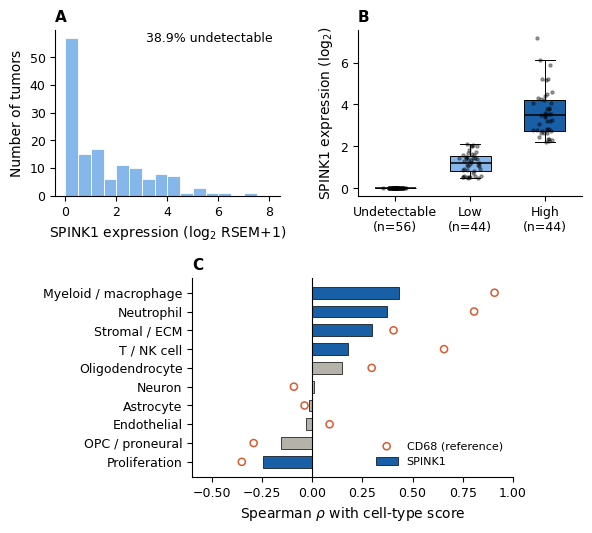

In [4]:
import matplotlib.pyplot as plt

plt.rcParams.update({'font.family': 'sans-serif', 'font.sans-serif': ['Arial', 'DejaVu Sans'],
                     'font.size': 9, 'axes.labelsize': 10, 'axes.linewidth': 0.8,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'legend.frameon': False, 'pdf.fonttype': 42})
PALETTE = {'Undetectable': '#B4B2A9', 'Low': '#85B7EB', 'High': '#185FA5'}
spink1 = coh['SPINK1_log2']

fig = plt.figure(figsize=(6.8, 5.8))
outer = fig.add_gridspec(2, 1, height_ratios=[1, 1.2], hspace=0.45)
top = outer[0].subgridspec(1, 2, wspace=0.35)
bottom = outer[1].subgridspec(1, 3, width_ratios=[0.33, 1, 0.12])
axA, axB, axC = fig.add_subplot(top[0]), fig.add_subplot(top[1]), fig.add_subplot(bottom[1])

axA.hist(spink1, bins=np.arange(0, 8.5, 0.5), color='#85B7EB', edgecolor='white', linewidth=0.6)
axA.set_xlabel('SPINK1 expression (log$_2$ RSEM+1)')
axA.set_ylabel('Number of tumors')
axA.text(0.97, 0.93, f'{(spink1 == 0).mean() * 100:.1f}% undetectable',
         transform=axA.transAxes, ha='right')

rng = np.random.default_rng(0)
for i, g in enumerate(GROUP_ORDER):
    v = coh.loc[coh['SPINK1_group'] == g, 'SPINK1_log2'].values
    axB.boxplot(v, positions=[i], widths=0.55, showfliers=False, patch_artist=True,
                medianprops=dict(color='black', lw=1.1),
                boxprops=dict(facecolor=PALETTE[g], edgecolor='black', lw=0.7),
                whiskerprops=dict(lw=0.7), capprops=dict(lw=0.7))
    axB.scatter(rng.normal(i, 0.07, len(v)), v, s=5, color='black', alpha=0.35, zorder=3)
axB.set_xticks(range(3))
axB.set_xticklabels([f'{g}\n(n={(coh["SPINK1_group"] == g).sum()})' for g in GROUP_ORDER])
axB.set_ylabel('SPINK1 expression (log$_2$)')

d = s3.sort_values('SPINK1')
y = np.arange(len(d))
axC.barh(y, d['SPINK1'], color=np.where(d['p_SPINK1'] < 0.05, '#185FA5', '#B4B2A9'),
         edgecolor='black', linewidth=0.5, height=0.62, label='SPINK1')
axC.scatter(d['CD68 (myeloid)'], y, s=26, facecolors='none', edgecolors='#D85A30',
            linewidths=1.1, zorder=3, label='CD68 (reference)')
axC.axvline(0, color='black', lw=0.8)
axC.set_yticks(y)
axC.set_yticklabels(d['cell_type_panel'])
axC.set_xlim(-0.6, 1.0)
axC.set_xticks([-0.5, -0.25, 0, 0.25, 0.5, 0.75, 1.0])
axC.set_xlabel('Spearman $\\rho$ with cell-type score')
axC.legend(loc='lower right', fontsize=8)

for ax, label in zip([axA, axB, axC], 'ABC'):
    ax.set_title(label, loc='left', fontweight='bold', fontsize=11)

for ext in ['png', 'pdf']:
    fig.savefig(os.path.join(RESULTS, f'Figure_1_SPINK1_expression_cell_context.{ext}'),
                dpi=600, bbox_inches='tight')
plt.show()